In [ ]:
# Colab: загрузите tourist-rag.zip в файлы сессии (или сделайте git clone своего репозитория)
!unzip -oq tourist-rag.zip
!pip install -q -e ./tourist-rag
!pip install -q sentence-transformers chromadb umap-learn plotly bitsandbytes accelerate gdown pyarrow
# ColBERT-реранкер из условия задания (необязательно). ragatouille 0.0.9 в свежем Colab падает на `langchain.retrievers`,
# поэтому ставим langchain-classic и подключаем шим (ячейка ниже). Если не взлетит — ноутбук пойдёт дальше без ColBERT.
!pip install -q ragatouille langchain-classic

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for touristrag (pyproject.toml) ... done


In [ ]:
import os, sys, inspect
for p in ("tourist-rag/src", "../src"):
    if os.path.isdir(p): sys.path.insert(0, os.path.abspath(p))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from touristrag.config import Config
from touristrag.utils import set_seed

# шим для ragatouille: устаревшие модули langchain переехали в langchain_classic (best-effort)
try:
    import importlib
    for m in ("retrievers", "retrievers.document_compressors", "retrievers.document_compressors.base"):
        sys.modules.setdefault(f"langchain.{m}", importlib.import_module(f"langchain_classic.{m}"))
except Exception as e:
    print("шим langchain пропущен:", repr(e)[:120])

pd.set_option("display.max_colwidth", 120)
cfg = Config()          # все гиперпараметры в одном месте
set_seed(cfg.seed)
cfg

Config(data_url='https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk', data_path='data/file.csv', artifacts_dir='artifacts', column_overrides={}, desc_strategy='concat', max_descriptions=3, max_captions=2, chunk_tokens=200, chunk_overlap=1, include_captions=True, embed_model='intfloat/multilingual-e5-base', vector_backend='chroma', retrieval_mode='hybrid', k_retrieve=20, k_context=4, rrf_k=60, context_order='edges', rerank_backend='cross-encoder', rerank_model=None, llm_model='Qwen/Qwen2.5-3B-Instruct', llm_4bit=False, max_new_tokens=300, n_eval=100, blind_ratio=0.5, seed=42)

In [ ]:
from touristrag.data import load_raw, detect_schema, standardize, decode_image

raw = load_raw(cfg.data_path, cfg.data_url)
print(raw.shape)
raw.head(3)

Downloading...
From (original): https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk
From (redirected): https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk&confirm=t&uuid=44984d14-b878-4c07-a42d-ac4ad3f70e22
To: /content/data/file.csv
100%|██████████| 672M/672M [00:07<00:00, 87.9MB/s]


(14634, 9)


,Unnamed: 0,Name,WikiData,City,Lon,Lat,description,image,en_txt
0,0,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBAUGBgUGCA4JCAcHCBEMDQoOFBEVFBMRExMWGB8bFhceFxMTGyUcHiAhIyMjFRomKSYiKR8i...,there are two people that are standing on a track in a stadium
1,1,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBAUGBgUGCA4JCAcHCBEMDQoOFBEVFBMRExMWGB8bFhceFxMTGyUcHiAhIyMjFRomKSYiKR8i...,arafed building with a blue and white exterior and a blue fence
2,2,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBAUGBgUGCA4JCAcHCBEMDQoOFBEVFBMRExMWGB8bFhceFxMTGyUcHiAhIyMjFRomKSYiKR8i...,there is a blue and white building with a clock on top


In [ ]:
schema = detect_schema(raw.columns, cfg.column_overrides)
print(schema)
assert schema["caption"], "BLIP-подписи не найдены: задайте cfg.column_overrides = {'caption': '<имя колонки>'}"
df = standardize(raw, schema)
df.drop(columns="image").head()

{'name': 'Name', 'wikidata_id': 'WikiData', 'city': 'City', 'lon': 'Lon', 'lat': 'Lat', 'caption': 'en_txt', 'description': 'description', 'image': 'image'}


,row_id,name,wikidata_id,city,lon,lat,description,caption
0,0,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,there are two people that are standing on a track in a stadium
1,1,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,arafed building with a blue and white exterior and a blue fence
2,2,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,there is a blue and white building with a clock on top
3,3,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,there is a blue and white building with a clock on top
4,4,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,there is a boat that is in the water near a building


,empty_%,unique,mean_len
column,,,
name,0.00,386,26.1
wikidata_id,17.47,297,6.9
city,0.00,4,10.9
lon,0.00,394,8.9
lat,0.00,394,8.9
description,17.47,246,27.0
image,0.00,13281,NaN
caption,0.00,10154,56.5
place_key,0.00,367,12.7


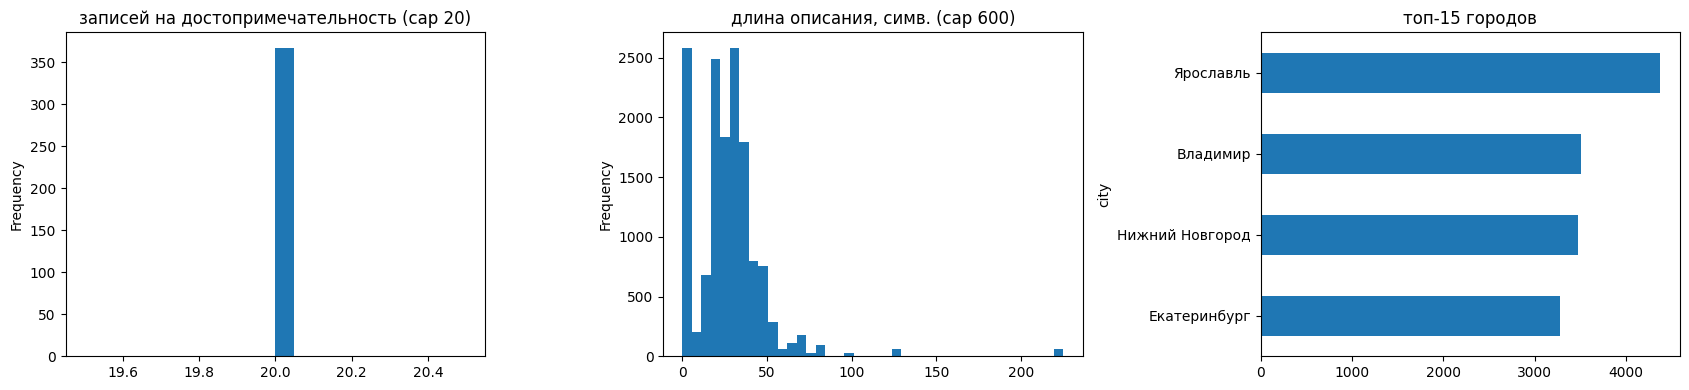

In [ ]:
from touristrag.eda import overview, plot_eda, show_images

from touristrag.data import place_key
df["place_key"] = place_key(df)
display(overview(df))
plot_eda(df); plt.show()

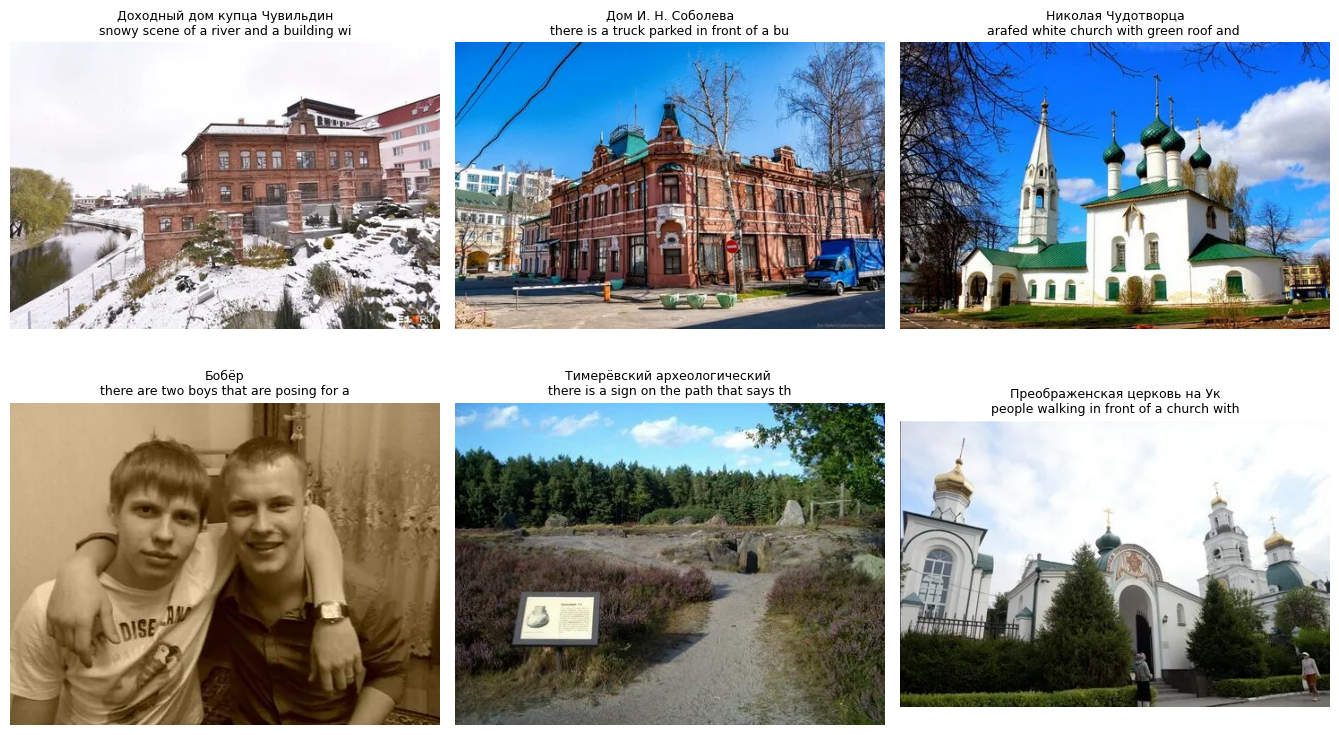

In [ ]:
show_images(df, n=6); plt.show()

In [ ]:
from touristrag.data import build_places

places_all = build_places(df, cfg.desc_strategy, cfg.max_descriptions, cfg.max_captions)
places_longest = build_places(df, "longest")
print(f"{len(df)} записей -> {len(places_all)} уникальных мест")
cmp = pd.DataFrame({"len_longest": places_longest.description.str.len(), "len_concat": places_all.description.str.len()})
print(cmp.describe().round(1))
places_all.drop(columns="image").head()

14634 записей -> 367 уникальных мест
       len_longest  len_concat
count        367.0       367.0
mean          26.7        26.7
std           23.3        23.3
min            0.0         0.0
25%           16.0        16.0
50%           27.0        27.0
75%           35.0        35.0
max          225.0       225.0


,place_id,place_key,name,city,lat,lon,description,caption,n_records
0,p00000,Q37996725,Динамо,Екатеринбург,56.845398,60.600349,спорткомплекс в Екатеринбурге,aerial view of a city with a large orange dome in the middle of the city; there is a building with a clock tower in ...,41
1,p00001,Q55209768,Дом обороны,Екатеринбург,56.834667,60.601882,здание в Екатеринбурге,cars are parked in front of a building with a large advertisement on the side; a black and white photo of a group of...,56
2,p00002,Q55154121,№28 Здание городской электростанции «Луч»,Екатеринбург,56.833691,60.607430,здание и достопримечательность в Екатеринбурге,there is a bridge that is going over a river with a building in the background; a black and white photo of a buildin...,26
3,p00003,Q55232375,№27 Дом Г.Н. Скрябина,Екатеринбург,56.834225,60.607075,Дом Е.Д. Скрябиной,there is a man standing outside of a building with a tree in front of it; snowy trees in front of a red brick buildi...,28
4,p00004,Q4306077,Литературная жизнь Урала XX века,Екатеринбург,56.842705,60.606716,,arafed brick building with a steeple and a man walking in front of it; there is a small building with a metal roof a...,27


In [ ]:
from touristrag.cleaning import tfidf_terms, flag_outliers, review_table, drop_places, stratified_sample

texts = (places_all.name + ". " + places_all.description + " " + places_all.caption).tolist()
terms = tfidf_terms(texts, top_n=30)
display(terms["frequent"].T); display(terms["rare"].T)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
term,with,of,in,and,building,the,arafed,on,there,front,...,man,church,green,middle,parked,walking,екатеринбурге,street,are,roof
df,345,340,285,264,253,226,207,172,168,162,...,70,68,66,60,60,60,56,54,53,51
idf,1.061644,1.0762,1.252091,1.328353,1.370749,1.483133,1.570545,1.754791,1.778184,1.814333,...,2.645403,2.673976,2.70339,2.797209,2.797209,2.797209,2.865032,2.90075,2.919099,2.956839


,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
term,1000,1905,advertisement,altar,american,araful,archway,arms,balls,baseball,...,certificates,chair,clothing,collage,colored,colorful,column,coming,conductor,corner
df,2,2,2,2,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,2,2
idf,5.809471,5.809471,5.809471,5.809471,5.809471,5.809471,5.809471,5.809471,5.809471,5.809471,...,5.809471,5.809471,5.809471,5.809471,5.809471,5.809471,5.809471,5.809471,5.809471,5.809471


In [ ]:
from touristrag.retrieval import Embedder
embedder = Embedder(cfg.embed_model)

flagged = flag_outliers(places_all, embedder)
print("помечено как мусор:", int(flagged.is_junk.sum()), "из", len(flagged))
review_table(flagged, 40)

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (7 outputs left out)

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

помечено как мусор: 12 из 367


,place_id,name,city,caption,rule_flag,zs_margin,tfidf_atyp,junk_score,is_junk
215,p00215,Кресень,Владимир,painting of a group of people in red and green clothing standing in the snow; arafed woman taking a selfie on the be...,pattern:\bselfie\b,0.047778,0.588456,8.730452,True
251,p00251,Мальчик с рогаткой,Владимир,"a man is standing and holding a pitchfork and a pitchfork in his hand, a man with a; a close up of a young girl hold...",person_only,0.029274,0.793741,8.525260,True
262,p00262,Макет ракеты-носителя Союз-ТМ,Владимир,a close up of a diagram of different rockets with different engines; a diagram of a rocket and other space objects o...,pattern:\bdiagram\b,0.024223,0.816986,8.414991,True
362,p00362,Ярославский зоопарк,Ярославль,a poster advertising a meeting of the national committee of the russian federation; araffe looking over a fence at t...,pattern:\bposter\b,0.015546,0.817908,7.991693,True
86,p00086,Дом дворянки Е. О. Селивановой,Екатеринбург,there is a black and white photo of a couple of people standing outside of a house; there is a man standing outside ...,pattern:cell ?phone,0.010190,0.679061,6.895080,True
281,p00281,Больница имени Н. В. Соловьёва,Ярославль,a picture of a building with a blue and white banner and a picture of a person on a; arafed man in a white lab coat ...,pattern:\bbanner\b,0.004987,0.700130,6.764217,True
240,p00240,Наука,Владимир,a poster for the conference of the international conference of the international conference of the international con...,pattern:\bposter\b,0.001035,0.684374,6.474535,True
143,p00143,Локомотив,Нижний Новгород,arafed banner in the stands at a soccer game with a soccer player on the field; arafed soccer player in green and re...,pattern:\bbanner\b,-0.012769,0.714866,5.975076,True
205,p00205,église arménienne de Vladimir,Владимир,a computer generated image of a rocky landscape with a moon in the distance; a view of a large white building with a...,pattern:\bcomputer\b,-0.014867,0.660117,5.634807,True
41,p00041,Уральский государственный колледж имени И.И. Ползунова,Екатеринбург,arafed building with a dome in front of it and a flower bed in front of it; people standing in a crowd holding a ban...,pattern:\bbanner\b,-0.026008,0.692324,5.185801,True


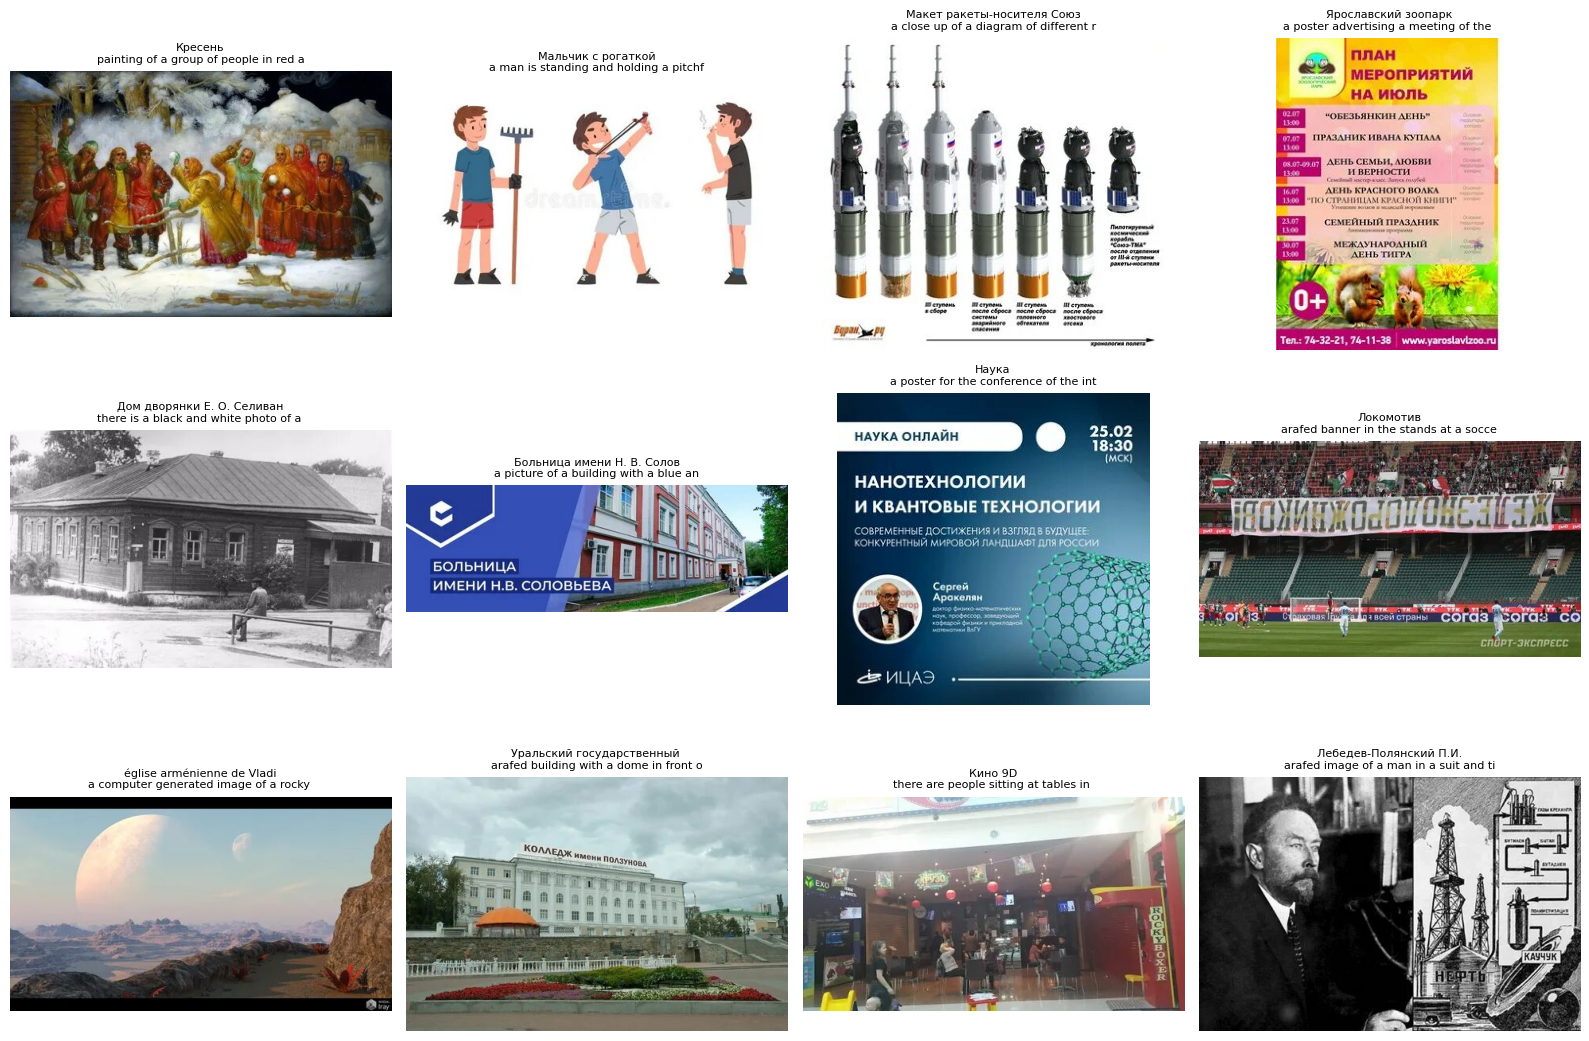

In [ ]:
def show_places(frame, n=12, cols=4):
    frame = frame[frame.image != ""].head(n)
    rows = (len(frame) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 3.6*rows))
    for ax in np.atleast_1d(axes).ravel(): ax.axis("off")
    for ax, r in zip(np.atleast_1d(axes).ravel(), frame.itertuples()):
        ax.imshow(decode_image(r.image)); ax.set_title(f"{r.name[:26]}\n{r.caption[:38]}", fontsize=8)
    plt.tight_layout(); plt.show()

show_places(flagged.sort_values("junk_score", ascending=False), n=12)

In [ ]:
BLACKLIST = []   # place_id, которые вы нашли руками и хотите убрать дополнительно
places = drop_places(flagged[~flagged.is_junk].drop(columns=["rule_flag","tfidf_atyp","zs_margin","junk_score","is_junk"]), BLACKLIST)
print("чистых мест:", len(places))

чистых мест: 355


In [ ]:
test_places = stratified_sample(places, n=100, by="city", seed=cfg.seed)
print(len(test_places), "мест,", test_places.city.nunique(), "городов")
test_places.city.value_counts().head(10)

100 мест, 4 городов


,count
city,
Екатеринбург,25
Владимир,25
Нижний Новгород,25
Ярославль,25


In [ ]:
from touristrag.pipeline import build_index, TouristRAG
from touristrag.retrieval import HybridRetriever, Reranker

os.makedirs("artifacts", exist_ok=True)
chunks, store, chunk_emb = build_index(places, embedder, cfg, store_path="artifacts/chroma")
ch = pd.DataFrame(chunks)
print(len(places), "мест ->", len(ch), "чанков;", ch.chunk_type.value_counts().to_dict())
ch.text.map(embedder.count_tokens).describe().round(1)

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

355 мест -> 642 чанков; {'caption': 355, 'description': 287}


,text
count,642.0
mean,40.0
std,16.8
min,10.0
25%,22.0
50%,48.0
75%,55.0
max,80.0


In [ ]:
retriever = HybridRetriever(embedder, store, chunks, cfg.rrf_k)
rr_ce = Reranker("cross-encoder", cfg.rerank_model)
try:
    rr_colbert = Reranker("colbert")           # ragatouille, как в условии
except Exception as e:
    rr_colbert = None; print("ragatouille недоступен:", repr(e)[:200])

from touristrag.llm import HFChat
llm = HFChat(cfg.llm_model, cfg.llm_4bit, cfg.max_new_tokens)
rag = TouristRAG(retriever, rr_ce, llm, cfg)

config.json:   0%|          | 0.00/795 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.27GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

... (17 outputs left out)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [ ]:
q = "Какой кремль находится в Нижнем Новгороде?"
for name, rr in [("без реранка", Reranker("none")), ("cross-encoder", rr_ce), ("ColBERT (ragatouille)", rr_colbert)]:
    if rr is None: continue
    hits = rr.rerank(q, retriever.retrieve(q, k=cfg.k_retrieve), top_k=5)
    print(f"{name:24s}", [h["name"] for h in hits])
res = rag.answer(q); print("\n", res["answer"])

без реранка              ['Нижегородский кремль', 'Нижегородский Кремль', 'Дмитриевская башня', 'Гарнизонная казарма', 'Северная башня']
cross-encoder            ['Нижегородский Кремль', 'Нижегородский кремль', 'Нижегородский кремль', 'Георгиевская башня', 'Борисоглебская башня']

 Нижегородский кремль находится в Нижнем Новгороде.


In [ ]:
from touristrag.viz import reduce_embeddings, plot_embeddings

mask = (ch.chunk_type == "description").to_numpy()
E, meta = chunk_emb[mask], ch[mask].reset_index(drop=True)
pca_xy, pca = reduce_embeddings(E, "pca")
umap_xy, umap_model = reduce_embeddings(E, "umap")
ev = pca.explained_variance_ratio_.sum()
f1 = plot_embeddings(pca_xy, meta.city, meta.name, f"PCA (объясн. дисперсия {ev:.1%})")
f2 = plot_embeddings(umap_xy, meta.city, meta.name, "UMAP (cosine)")
os.makedirs("results", exist_ok=True); f1.write_html("results/pca.html"); f2.write_html("results/umap.html")
f1.show(); f2.show()

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [ ]:
from touristrag.evaluation import (data_preprocess, run_rag_on_dataset, answer_relevancy, summarize,
                                   faithfulness, context_precision, context_recall, evaluate_retrieval)
print(inspect.getsource(data_preprocess)[:1800]); print(inspect.getsource(answer_relevancy))

def data_preprocess(places: pd.DataFrame, llm_fn=None, n: int = 100, blind_ratio: float = 0.5,
                    seed: int = 42, by: str = "city") -> pd.DataFrame:
    """Build the RAGAS-format evaluation frame from clean, stratified places.

    Columns: question, ground_truth(s), answer, contexts (filled later by `run_rag_on_dataset`)
    plus `place_id` (gold landmark for retrieval metrics) and `qtype` (named | blind).
    Without an `llm_fn` falls back to template questions. Questions are LLM-generated from the
    description (cookbook-style synthetic QA); half are "blind" so retrieval can't just match the name.
    """
    sample = stratified_sample(places, n=n, by=by, seed=seed)
    rng = np.random.default_rng(seed)
    blind_mask = rng.random(len(sample)) < blind_ratio
    rows, failures = [], 0
    for r, blind in zip(progress(list(sample.itertuples(index=False)), desc="generating QA"), blind_mask):
        question = answer = None
        if llm_fn is not None:
            

In [ ]:
llm_fn   = lambda p: llm(p)
embed_fn = lambda xs: embedder.encode(xs, kind="query")

ds = data_preprocess(places, llm_fn, n=cfg.n_eval, blind_ratio=cfg.blind_ratio, seed=cfg.seed)
ds[["place_id","qtype","question","ground_truth"]].head(8)

generating QA:   0%|          | 0/100 [00:00<?, ?it/s]

[data_preprocess] 4/100 generations fell back to templates


,place_id,qtype,question,ground_truth
0,p00079,blind,Что видно на фотографии рядом с зданием Дома Промышленности в Екатеринбурге?,"Фотография показывает здание с многочисленными окнами и людьми, прогуливающимися вокруг него, а также небо и горы в ..."
1,p00186,blind,"Что видно в центре фотографии, окруженное зеленым ландшафтом?","На фотографии видна большая здание с золотым куполом в центре парка, а за ним — улица с зданием и телеграфной будкой."
2,p00119,blind,Что видно на фотографии рядом с круглой башней Нижегородского кремля?,"На фотографии видна арка из кирпичей, ведущая к кирпичной башне с часами на верху. Люди идут по пешеходной дорожке в..."
3,p00308,blind,Что видно на фотографии рядом с Михайловскими курганами?,"На фотографии видна гора Михайловские курганы с тропинкой, людьми и деревьями в поле в туманной погоде."
4,p00318,blind,Какой тип зданий показан на первой фотографии? Имеется ли на ней указание на наличие велосипеда?,"На первой фотографии изображен белый дом с золотым куполом, а перед ним стоит велосипед."
5,p00261,blind,Что видно на фотографии рядом с маленьким желтым зданием с золотым шпилем в снегу?,"На фотографии видна небольшая желтая церковь с золотым шпилем, установленная среди снега. На крыше здания установлен..."
6,p00064,blind,Что изображено на фотографии рядом с могилой?,"На фотографии видно группу людей вокруг могилы и архитектурный фрагмент с забором, палками и лодкой в воде."
7,p00108,blind,"Что видно на фотографии рядом с арапед ступенями, ведущими к холму с телескопом?","На фотографии видна арапед ступенчатая лестница, ведущая к холму с телескопом в центре, а также вид на замок на холм..."


In [20]:
ds = run_rag_on_dataset(ds, rag)
ar, details = answer_relevancy(ds.question, ds.answer, llm_fn, embed_fn, n_gen=3, return_details=True)
ds["answer_relevancy"] = ar
print(f"answer_relevancy = {np.nanmean(ar):.3f}   (валидных {np.isfinite(ar).sum()}/{len(ar)})")
print(ds.groupby("qtype").answer_relevancy.mean().round(3).to_dict())
ds[["question","answer","answer_relevancy"]].sort_values("answer_relevancy").head(5)

RAG:   0%|          | 0/100 [00:00<?, ?it/s]

answer_relevancy = 0.807   (валидных 100/100)
{'blind': 0.801, 'named': 0.902}


,question,answer,answer_relevancy
4,Какой тип зданий показан на первой фотографии? Имеется ли на ней указание на наличие велосипеда?,На первой фотографии показан старинный велосипед. На фотографии нет указания на наличие рядом с ним велосипеда.,0.0
57,Что происходит в зале с бочками из стекла?,В этом описании нет информации о зале с бочками из стекла. Данный факт не соответствует ни одной из представленных в...,0.0
62,Что видно на фотографии архитектурного здания с телескопом и толпой людей?,"На фотографии видна толпа людей, но нет информации о здании с телескопом. Возможно, это изображение другого объекта.",0.0
42,Какие элементы можно заметить на черно-белой фотографии улицы с зданием и телескопом?,На черно-белой фотографии улицы с зданием и телескопом можно заметить телескоп на крыше здания. Однако из предоставл...,0.0
52,What is the nighttime view depicted in the photo and what does it resemble?,В этом случае информация о ночном виду не указана в предоставленных данных. Мы знаем только координаты и вид изображ...,0.0


In [21]:
q_emb = embedder.encode(ds.question.tolist(), kind="query")
f = plot_embeddings(umap_xy, meta.city, meta.name, "UMAP: места и тестовые вопросы (×)",
                    query_coords=umap_model.transform(q_emb), query_hover=ds.question)
f.write_html("results/umap_queries.html"); f.show()

In [22]:
def run_ablation(ds):
    variants = {"dense": ("dense", Reranker("none")), "bm25": ("bm25", Reranker("none")),
                "hybrid (RRF)": ("hybrid", Reranker("none")), "hybrid + cross-encoder": ("hybrid", rr_ce)}
    if rr_colbert is not None: variants["hybrid + ColBERT (ragatouille)"] = ("hybrid", rr_colbert)
    rows = {}
    for name, (mode, rr) in variants.items():
        rag.reranker = rr
        res = evaluate_retrieval(lambda q: rag.rank_places(q, mode=mode, rerank=rr.backend != "none"), ds)
        rows[name] = {**res["all"], **{f"mrr[{t}]": res[t]["mrr"] for t in res if t != "all"}}
    rag.reranker = rr_ce
    return pd.DataFrame(rows).T.round(3)

ablation = run_ablation(ds); ablation.to_csv("results/ablation.csv"); ablation

retrieval:   0%|          | 0/100 [00:00<?, ?it/s]

retrieval:   0%|          | 0/100 [00:00<?, ?it/s]

retrieval:   0%|          | 0/100 [00:00<?, ?it/s]

retrieval:   0%|          | 0/100 [00:00<?, ?it/s]

,hit@1,hit@3,hit@5,hit@10,mrr,mrr[blind],mrr[named]
dense,0.50,0.57,0.62,0.72,0.560,0.532,1.0
bm25,0.28,0.33,0.35,0.39,0.313,0.269,1.0
hybrid (RRF),0.34,0.43,0.53,0.66,0.419,0.382,1.0
hybrid + cross-encoder,0.61,0.74,0.75,0.76,0.675,0.655,1.0


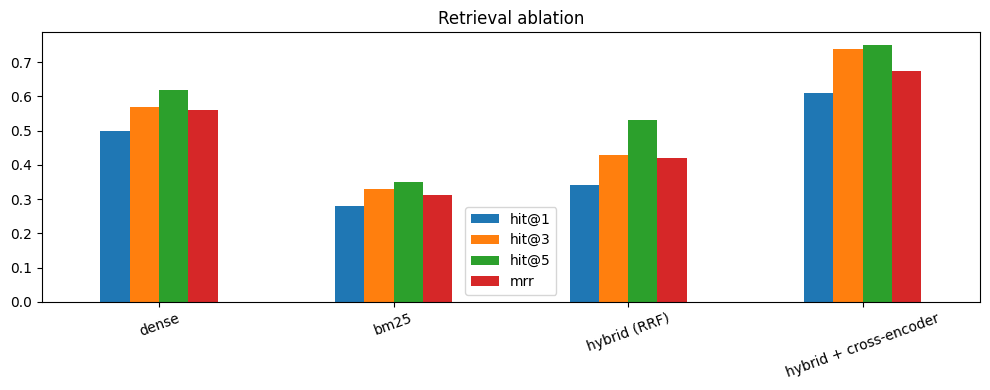

In [28]:
ablation[["hit@1","hit@3","hit@5","mrr"]].plot.bar(figsize=(10,4), rot=20, title="Retrieval ablation"); plt.tight_layout(); plt.show()

In [29]:
rag.reranker = rr_ce
names = places.set_index("place_id").name
bad = ds[[r.place_id not in r.retrieved_place_ids[:3] for r in ds.itertuples()]]
print(f"промахов top-3: {len(bad)}/{len(ds)}")
for r in bad.head(5).itertuples():
    print(f"\n[{r.qtype}] {r.question}\n  gold: {r.name}\n  got : {[names[i] for i in r.retrieved_place_ids[:3]]}")

промахов top-3: 26/100

[blind] Что видно в центре фотографии, окруженное зеленым ландшафтом?
  gold: Здание Присутственных мест. "Палаты"
  got : ['Владимиро-Суздальский музей-заповедник (центральный офис)', 'Исторический центр Ярославля', 'Владимирским железнодорожникам погибшим в ВОВ']

[blind] Что видно на фотографии рядом с круглой башней Нижегородского кремля?
  gold: Тайницкая башня
  got : ['Борисоглебская башня', 'Часовая башня', 'Нижегородский кремль']

[blind] Какой тип зданий показан на первой фотографии? Имеется ли на ней указание на наличие велосипеда?
  gold: Николо-Сковородский монастырь
  got : ['Старинный велосипед', 'Владимирская духовная семинария', 'Белокаменные памятники Владимира и Суздаля']

[blind] Какой тип зданий показан на фотографии, с большим белым строением с золотым куполом и башней-часовни, а впереди видна река?
  gold: Спасо-преображенская церковь
  got : ['Белокаменные памятники Владимира и Суздаля', 'Иоанно-Предтеченский Кафедральный собор', 'Свято-Н

In [30]:
for q in ["Что такое Золотые ворота во Владимире?", "Какая башня в Екатеринбурге белого цвета?", "Расскажи про соборную мечеть в Нижнем Новгороде"]:
    r = rag.answer(q); print("Q:", q, "\nA:", r["answer"], "\n   источники:", [h["name"] for h in r["hits"]], "\n")

Q: Что такое Золотые ворота во Владимире? 
A: Золотые ворота - это памятник XII века, находящийся в Владимире. Он является одной из важнейших достопримечательностей города. 
   источники: ['Золотые ворота', 'Собор Успения Пресвятой Богородицы', 'Бывшая водонапорная башня', 'Военно-историческая экспозиция (Золотые ворота)'] 

Q: Какая башня в Екатеринбурге белого цвета? 
A: Белой башня в Екатеринбурге — это Борисоглебская башня, она находится в Нижнем Новгороде, но имеет белый цвет. В Екатеринбурге белого цвета башни нет в перечисленных достопримечательностях. 
   источники: ['Белая башня', 'Белая башня', 'Борисоглебская башня', 'Водонапорная башня'] 

Q: Расскажи про соборную мечеть в Нижнем Новгороде 
A: Нижегородская соборная мечеть находится в Нижнем Новгороде. Это место религиозного значения для мусульман города. Её координаты: 56.3234, 44.0376. 
   источники: ['Нижегородская соборная мечеть', 'Собор Архангела Михаила', 'Храм Живоначальной Троицы', 'Собор Александра Невского'] 



In [31]:
sub = ds.sample(30, random_state=cfg.seed)
scores = {
    "answer_relevancy":  ds.answer_relevancy.to_numpy(),
    "faithfulness":      faithfulness(sub.question, sub.answer, sub.contexts, llm_fn),
    "context_precision": context_precision(sub.question, sub.ground_truth, sub.contexts, llm_fn),
    "context_recall":    context_recall(sub.ground_truth, sub.contexts, llm_fn),
}
summary = summarize(scores); summary.round(3)

,mean,n_valid,n
metric,,,
answer_relevancy,0.807,100,100
faithfulness,0.725,29,30
context_precision,0.834,30,30
context_recall,0.611,30,30


In [32]:
ds.to_csv("results/eval_samples.csv", index=False); summary.to_csv("results/ragas_summary.csv")
import json; json.dump({"config": cfg.__dict__, "ablation": ablation.to_dict("index"), "ragas": summary["mean"].to_dict()},
                       open("results/metrics.json","w"), ensure_ascii=False, indent=2, default=str)